# Does the fixed sampled workflow transfer to two new instances?

This notebook applies the previous finite-shot schedule to a **three-vertex triangle** and a **second two-qubit Hamiltonian**. The circuit family, shot schedule, acceptance margin and stopping rule are fixed. We do not retune them after observing these results.

Each task starts at the **same parameters across seeds** `7`, `19`, and `41`: QAOA starts at `(gamma,beta)=(0.2,0.1)`, and VQE at `theta=0.6`. Varying the seed now isolates seeded sampling variation in this ideal model rather than jointly changing the initial point. Three seeds remain a small teaching check, not a distributional performance guarantee.

Independent ideal measurements are simulated by drawing counts from explicit circuit statevector probabilities. Measured outcomes and their descriptive standard errors drive every parameter decision. Exact values are computed only afterward to audit quality and display the trajectories. Failed targets remain visible.

Use the pinned Python 3.12 environment. The notebook loads its worktree source explicitly or a matching **portability** `optimization.py` download placed beside it. Saved outputs serve a static site without a live kernel. QAOA and VQE follow the original algorithm papers {cite:p}`opt_qaoa2014,opt_vqe2014`. The original implementation and notebook are MIT; Qiskit core, NumPy and Matplotlib are credited with exact versions in the chapter {cite:p}`opt_qiskit262,opt_numpy254,opt_matplotlib3112`.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import platform
import sys

# Select the actual worktree source, or one explicit standalone download.
# Do not silently resolve the original checkout's editable installation.
cwd = Path.cwd().resolve()
candidates = [
    ("checkout", cwd / "src/openquantum/optimization.py"),
    ("checkout", cwd.parent / "src/openquantum/optimization.py"),
    ("standalone portability download", cwd / "optimization.py"),
    ("standalone portability download", cwd / "notebooks/optimization.py"),
]
selected = next(((kind, path.resolve()) for kind, path in candidates if path.is_file()), None)
if selected is None:
    raise FileNotFoundError("Save portability/optimization.py beside this notebook, or run from its checkout.")
source_kind, module_path = selected
spec = importlib.util.spec_from_file_location("optimization_portability_notebook_source", module_path)
opt = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = opt
spec.loader.exec_module(opt)
assert Path(opt.__file__).resolve() == module_path
if not hasattr(opt, "run_portability_demo"):
    raise ImportError("Use the portability optimization.py download; the older module lacks the portability workflow.")
# Keep the actual path in the kernel; avoid publishing private absolute paths.
print({"source": source_kind,
       "implementation_sha256": hashlib.sha256(module_path.read_bytes()).hexdigest(),
       "python": platform.python_version(),
       "packages": {name: importlib.metadata.version(name) for name in ("qiskit", "numpy", "matplotlib")}})

import math
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector


{'source': 'checkout', 'implementation_sha256': 'a617b5e8d43b648427e5ceaa5e35d3f50ea14c02464465084f23f457ffb5855d', 'python': '3.12.14', 'packages': {'qiskit': '2.6.2', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}}


## New tasks, unchanged circuit families

The triangle has edges $(0,1),(1,2),(0,2)$. The task maximizes $C(z)=\sum_{(u,v)}[z_u\ne z_v]$, and training minimizes the negative sampled cut mean. Enumerating all eight assignments gives maximum cut two. Bitstrings read $q_2q_1q_0$.

QAOA prepares $|+\rangle^{\otimes3}$ with H on all three qubits. It uses CX–RZ$(−\gamma)$–CX on each edge and RX$(2\beta)$ on every qubit. Angles are radians with $R_P(\alpha)=e^{-i\alpha P/2}$. A single all-Z group scores all three edges jointly. The cycle's earlier scalar energy formula does not apply to this graph; below we independently apply the diagonal cost phase and an explicit NumPy tensor-product mixer.

For VQE, the new dimensionless Hamiltonian is

$$H=-0.8Z_0-0.6Z_1+0.4X_0X_1.$$

The ansatz still prepares $|00\rangle$, applies RY$(\theta)$ on qubit zero, then CX$(0,1)$. One joint all-Z group scores $-0.8Z_0-0.6Z_1$, retaining covariance; the all-X group scores $0.4X_0X_1$ after H basis changes on both qubits. Every shot needs a fresh preparation.

The post-run reference ground energy is $-\sqrt{2.12}$. The ansatz expectation is $E(\theta)=-1.4\cos\theta+0.4\sin\theta$. Full matrix diagonalization below checks the reference rather than assuming that the ansatz subspace contains the global minimum.


## Preserved schedule and predeclared quality checks

The initial objective uses 256 shots per group. Each of 32 sweeps freshly measures the incumbent and all negative and positive coordinate proposals, then accepts the best proposal only if its sampled decrease exceeds twice the combined estimated standard error. The four eight-sweep blocks remain:

| Sweeps | Coordinate step, radians | Shots per group |
|---|---:|---:|
| 1–8 | 0.4 | 256 |
| 9–16 | 0.2 | 512 |
| 17–24 | 0.1 | 1,024 |
| 25–32 | 0.05 | 2,048 |

The rule is a fixed-budget heuristic, not a calibrated significance test or a convergence certificate. After the schedule ends, each final state receives fresh validation with 4,096 shots per group. Validation and exact audits do not choose training moves.

The predeclared post-run targets are expected triangle cut at least **1.90** and exact VQE energy gap at most **0.03** above $-\sqrt{2.12}$. These refer to exact post-run quality, not uncertainty on the sampled estimate. All seeds retain the same initial point per task. Algorithm IDs 2 and 3 distinguish the new tasks from earlier random streams; PCG64 uses `SeedSequence([seed, algorithm_id], spawn_key=(family, call_index, group_index))`, with family zero for training and one for validation. Stream separation supports reproducibility; pseudorandom keys do not themselves prove the independent-sampling model.


In [2]:
# The same finite-shot settings run on two new explicitly stated inputs.
portable = opt.run_portability_demo()
assert portable["exact_diagnostics_used_for_optimization"] is False
assert portable["physical_resource_estimate"] is None
for algorithm, initial in (("qaoa", [.2, .1]), ("vqe", [.6])):
    assert [run["seed"] for run in portable[algorithm]["runs"]] == [7, 19, 41]
    for run in portable[algorithm]["runs"]:
        np.testing.assert_allclose(run["initial"], initial, rtol=0, atol=1e-14)
print({"new_instance_seed_cases": sum(len(portable[a]["runs"]) for a in ("qaoa", "vqe")),
       "training_modeled_shots": portable["training_shots"],
       "fresh_validation_modeled_shots": portable["validation_shots"],
       "total_modeled_shots": portable["total_shots"],
       "workflow_CPU_wall_seconds": portable["workflow_wall_seconds"]})


{'new_instance_seed_cases': 6, 'training_modeled_shots': 1016064, 'fresh_validation_modeled_shots': 36864, 'total_modeled_shots': 1052928, 'workflow_CPU_wall_seconds': 1.3606575270000576}


In [3]:
edges = ((0, 1), (1, 2), (0, 2))
n_qubits = 3
cut_values = np.array([sum(((z >> u) & 1) != ((z >> v) & 1) for u, v in edges)
                       for z in range(1 << n_qubits)], dtype=float)
np.testing.assert_array_equal(cut_values, opt.maxcut_values(n_qubits, edges))
assert cut_values.max() == 2
I = np.eye(2)
X = np.array([[0., 1.], [1., 0.]])
Z = np.diag([1., -1.])
reference_hamiltonian = -.8*np.kron(I, Z) - .6*np.kron(Z, I) + .4*np.kron(X, X)
np.testing.assert_allclose(portable["vqe"]["reference"]["matrix"], reference_hamiltonian, rtol=0, atol=1e-14)
assert {tuple(edge) for edge in portable["qaoa"]["edges"]} == set(edges)
reference_spectrum = np.linalg.eigvalsh(reference_hamiltonian)
reference_energy = float(reference_spectrum[0])
np.testing.assert_allclose(reference_energy, -np.sqrt(2.12), rtol=0, atol=1e-14)


def triangle_reference(parameters):
    gamma, beta = parameters
    # An independent 8-dimensional application of exp(-i gamma C).
    state = np.ones(8, dtype=complex)/np.sqrt(8)
    state *= np.exp(-1j*gamma*cut_values)
    rx = np.cos(beta)*I - 1j*np.sin(beta)*X
    mixer = np.kron(rx, np.kron(rx, rx))
    state = mixer @ state
    return float((np.abs(state)**2) @ cut_values)


# These fixed reference checks are separate from optimizer decisions.
for angles in ((.2, .1), (-.6, .3), (.8, -.2)):
    circuit_state = Statevector.from_instruction(opt.build_qaoa_circuit(n_qubits, edges, [angles[0]], [angles[1]]))
    np.testing.assert_allclose(circuit_state.probabilities() @ cut_values, triangle_reference(angles), rtol=0, atol=1e-12)
print({"triangle_maximum_cut": float(cut_values.max()),
       "maximum_cut_bitstrings": [f"{z:03b}" for z in np.flatnonzero(cut_values == 2)],
       "new_Hamiltonian_spectrum": reference_spectrum.tolist(), "ground_energy": reference_energy})


{'triangle_maximum_cut': 2.0, 'maximum_cut_bitstrings': ['001', '010', '011', '100', '101', '110'], 'new_Hamiltonian_spectrum': [-1.4560219778561037, -0.4472135954999579, 0.44721359549995804, 1.4560219778561037], 'ground_energy': -1.4560219778561037}


## Reconstruct the decisions from measured data

The following check reconstructs every observed mean and sample variance from its measured counts. It then replays the parameter decisions using **only** measured estimates, standard errors and the prescribed margin. Exact audit fields are excluded from this replay.

All rejected proposals remain in the record and count toward the workload. Re-estimating the incumbent means the displayed sampled trajectory need not be monotone, even when accepted parameter updates appear favorable. The main chapter's native MyST table is generated independently by the sampled artifact script; this notebook reports its own fresh execution.


In [4]:
def outcome_score(algorithm, group, bits):
    z = int(bits, 2)
    if algorithm == "qaoa":
        return float(sum(((z >> u) & 1) != ((z >> v) & 1) for u, v in edges))
    if group["group"] == "all_z":
        return -.8*(1 - 2*((z >> 0) & 1)) - .6*(1 - 2*((z >> 1) & 1))
    return .4*(1 - 2*((z >> 0) & 1))*(1 - 2*((z >> 1) & 1))


seen_stream_keys = set()
for algorithm in ("qaoa", "vqe"):
    dimension = 2 if algorithm == "qaoa" else 1
    expected_training_calls = 1 + 32*(1 + 2*dimension)
    expected_training_shots = (1 if algorithm == "qaoa" else 2)*(256 + (1 + 2*dimension)*8*(256 + 512 + 1024 + 2048))
    for run in portable[algorithm]["runs"]:
        assert run["objective_evaluations"] == expected_training_calls
        assert run["iteration_count"] == 32
        assert run["stop_reason"] == "fixed_schedule_exhausted"
        assert run["total_shots"] == expected_training_shots
        calls = run["evaluations"]
        for call in calls + [run["validation"]]:
            means, mean_variances = [], []
            for group in call["groups"]:
                assert sum(group["counts"].values()) == group["shots"]
                assert group["rng"]["entropy"] == [run["seed"], 2 if algorithm == "qaoa" else 3]
                stream_key = tuple(group["rng"]["stream_key"])
                assert stream_key not in seen_stream_keys
                seen_stream_keys.add(stream_key)
                mean = sum(count*outcome_score(algorithm, group, bits)
                           for bits, count in group["counts"].items()) / group["shots"]
                variance = sum(count*(outcome_score(algorithm, group, bits) - mean)**2
                               for bits, count in group["counts"].items()) / (group["shots"] - 1)
                np.testing.assert_allclose(mean, group["estimate"], rtol=0, atol=1e-12)
                np.testing.assert_allclose(variance, group["sample_variance"], rtol=1e-12, atol=1e-12)
                means.append(mean)
                mean_variances.append(variance/group["shots"])
            signed_mean = -sum(means) if algorithm == "qaoa" else sum(means)
            np.testing.assert_allclose(signed_mean, call["objective_estimate"], rtol=0, atol=1e-12)
            np.testing.assert_allclose(np.sqrt(sum(mean_variances)), call["estimated_standard_error"], rtol=1e-12, atol=1e-12)
        point = (np.array(run["initial"]) + np.pi) % (2*np.pi) - np.pi
        for iteration in run["iterations"]:
            incumbent = calls[iteration["incumbent_evaluation"]]
            proposals = [calls[index] for index in iteration["proposal_evaluations"]]
            np.testing.assert_allclose(incumbent["parameters"], point, rtol=0, atol=1e-12)
            best = min(proposals, key=lambda item: item["objective_estimate"])
            margin = 2*np.hypot(incumbent["estimated_standard_error"], best["estimated_standard_error"])
            accepted = incumbent["objective_estimate"] - best["objective_estimate"] > margin
            assert accepted == iteration["accepted"]
            assert best["index"] == iteration["best_proposal_evaluation"]
            if accepted:
                point = np.array(best["parameters"])
            np.testing.assert_allclose(iteration["parameters_after"], point, rtol=0, atol=1e-12)
        np.testing.assert_allclose(run["parameters"], point, rtol=0, atol=1e-12)
        assert all(group["rng"]["spawn_key"][0] == 0 for call in calls for group in call["groups"])
        assert all(group["rng"]["spawn_key"][0] == 1 for group in run["validation"]["groups"])
print("Reconstructed all 780 training/validation objective calls from counts and replayed all 192 sampled sweeps.")


Reconstructed all 780 training/validation objective calls from counts and replayed all 192 sampled sweeps.


## Sampled trajectories and post-decision exact audits

Solid lines show sampled estimates at the chosen states after each sweep: the accepted proposal estimate after an update, or the fresh incumbent estimate otherwise. Dashed lines show the exact expectation of those same parameters, computed after training. The exact curves do not drive the search. Colors identify the three predeclared seed and initialization pairs.

Expected cut is plotted with a positive sign, reversing the negative objective minimized by QAOA. VQE is plotted with the energy sign used by the optimizer. The reference lines are the triangle's classical maximum cut and the Hamiltonian's exact ground energy.


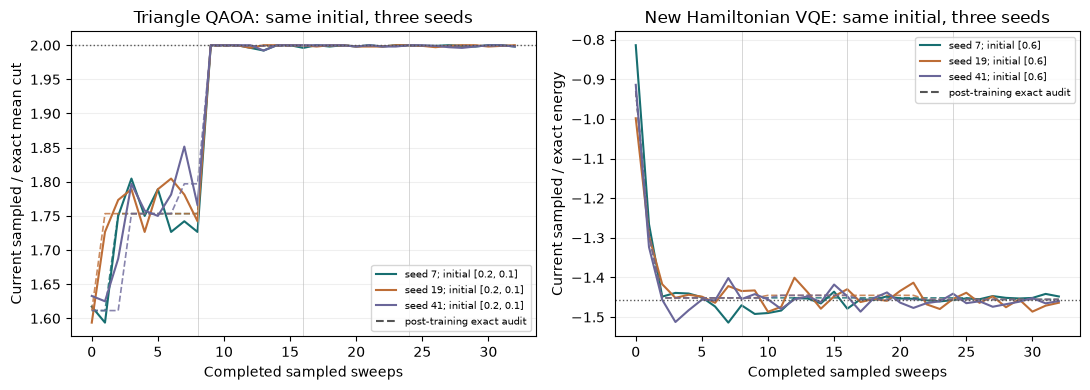

In [5]:
from matplotlib.lines import Line2D
colors = ("#176e70", "#bd6d36", "#6a6699")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, algorithm in zip(axes, ("qaoa", "vqe")):
    sign = -1 if algorithm == "qaoa" else 1
    handles = []
    for color, run in zip(colors, portable[algorithm]["runs"]):
        calls = run["evaluations"]
        selected_calls = [calls[0]] + [calls[it["best_proposal_evaluation"] if it["accepted"] else it["incumbent_evaluation"]]
                                        for it in run["iterations"]]
        observed = [sign*call["objective_estimate"] for call in selected_calls]
        audit = [sign*calls[0]["exact_objective_audit"]] + [sign*it["exact_objective_after_audit"]
                                                                       for it in run["iterations"]]
        line, = ax.plot(range(33), observed, color=color, lw=1.5, label=f"seed {run['seed']}; initial {run['initial']}")
        ax.plot(range(33), audit, color=color, lw=1.2, ls="--", alpha=.8)
        handles.append(line)
    target = 2 if algorithm == "qaoa" else reference_energy
    ax.axhline(target, color="#555555", lw=1, ls=":")
    ax.set(xlabel="Completed sampled sweeps", ylabel="Current sampled / exact mean cut" if algorithm == "qaoa" else "Current sampled / exact energy",
           title="Triangle QAOA: same initial, three seeds" if algorithm == "qaoa" else "New Hamiltonian VQE: same initial, three seeds")
    for boundary in (8, 16, 24):
        ax.axvline(boundary, color="#bbbbbb", lw=.6, alpha=.7)
    handles.append(Line2D([0], [0], color="#555555", ls="--", label="post-training exact audit"))
    ax.legend(handles=handles, fontsize=7.5, loc="best")
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
from IPython.display import display
display(fig)
plt.close(fig)


## Independent final readout

The final validation counts come from a separate random-stream family at the selected parameters. Markers show the validation sample means with **one estimated standard error**; these error bars are descriptive, not rigorous confidence intervals. Hollow markers show exact post-training expectations. The separate Hoeffding radii printed below give 95% bounds for each independently validated fixed mean, conditional on the trained parameters. They do not cover the adaptive training path simultaneously.

For QAOA, one group uses 4,096 shots. VQE uses 4,096 shots in each of two groups, totaling 8,192 state preparations. A sampled energy can lie below the ground energy through statistical fluctuation.


The separate validation-precision target is absolute error at most **0.10** with **95% coverage for each fixed estimate** under the ideal independent-sampling model. The triangle score range is two; the new VQE group ranges are 2.8 and 0.8. We recompute their Hoeffding radii below. Supporting this readout precision is separate from meeting the post-run exact cut or energy-quality target; neither statement certifies optimizer success over seeds.


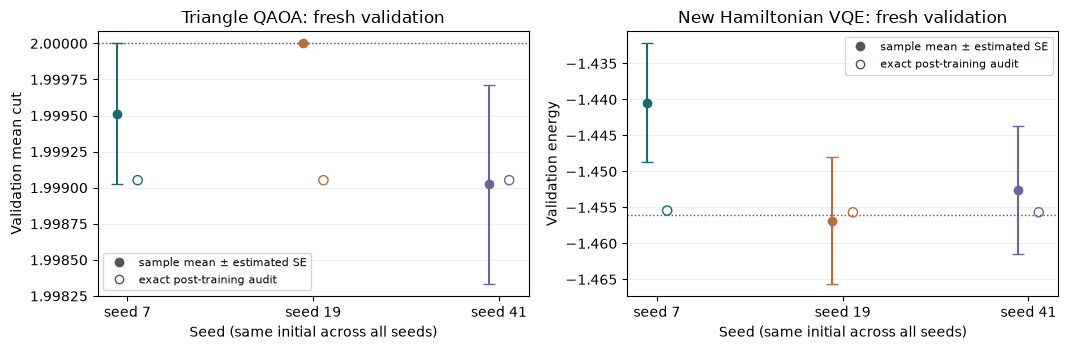

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.6))
for ax, algorithm in zip(axes, ("qaoa", "vqe")):
    sign = -1 if algorithm == "qaoa" else 1
    runs = portable[algorithm]["runs"]
    for position, (color, run) in enumerate(zip(colors, runs)):
        validation = run["validation"]
        ax.errorbar(position-.055, sign*validation["objective_estimate"],
                    yerr=validation["estimated_standard_error"], color=color, fmt="o", capsize=4)
        ax.scatter(position+.055, sign*validation["exact_objective_audit"],
                   facecolors="none", edgecolors=color, s=44, zorder=3)
    ax.axhline(2 if algorithm == "qaoa" else reference_energy, color="#555555", ls=":", lw=1)
    ax.set(xticks=range(3), xticklabels=[f"seed {run['seed']}" for run in runs],
           xlabel="Seed (same initial across all seeds)", ylabel="Validation mean cut" if algorithm == "qaoa" else "Validation energy",
           title="Triangle QAOA: fresh validation" if algorithm == "qaoa" else "New Hamiltonian VQE: fresh validation")
    ax.legend(handles=[Line2D([0], [0], marker="o", color="#555555", linestyle="none", label="sample mean ± estimated SE"),
                       Line2D([0], [0], marker="o", markerfacecolor="none", color="#555555", linestyle="none", label="exact post-training audit")], fontsize=8)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
display(fig)
plt.close(fig)


In [7]:
for algorithm in ("qaoa", "vqe"):
    print(algorithm.upper())
    sign = -1 if algorithm == "qaoa" else 1
    for run in portable[algorithm]["runs"]:
        validation = run["validation"]
        widths = (2.0,) if algorithm == "qaoa" else (2.8, .8)
        for group, width in zip(validation["groups"], widths):
            np.testing.assert_allclose(group["outcome_max"]-group["outcome_min"], width, rtol=0, atol=1e-14)
        independent_radius = np.sqrt(sum(width**2/group["shots"] for width, group in zip(widths, validation["groups"]))*np.log(40)/2)
        np.testing.assert_allclose(validation["hoeffding_95_absolute_mean_radius"], independent_radius, rtol=0, atol=1e-14)
        assert validation["precision_target_supported_by_bound"] == (independent_radius <= .10)
        print({"seed": run["seed"], "initial": run["initial"], "final_parameters_radians": run["parameters"],
               "training_objective_calls": run["objective_evaluations"], "independent_validation_calls": 1,
               "training_modeled_shots": run["total_shots"], "validation_modeled_shots": validation["total_shots"],
               "accepted_proposals": run["accepted_proposals"], "rejected_proposals": run["rejected_proposals"],
               "validation_mean": sign*validation["objective_estimate"],
               "exact_post_training_mean": sign*validation["exact_objective_audit"],
               "validation_95_Hoeffding_radius": validation["hoeffding_95_absolute_mean_radius"],
               "exact_quality_target_met": run["target_met_audit"],
               "validation_precision_supported_by_bound": validation["precision_target_supported_by_bound"]})


QAOA
{'seed': 7, 'initial': [0.2, 0.1], 'final_parameters_radians': [0.6000000000000001, 0.30000000000000027], 'training_objective_calls': 161, 'independent_validation_calls': 1, 'training_modeled_shots': 153856, 'validation_modeled_shots': 4096, 'accepted_proposals': 2, 'rejected_proposals': 126, 'validation_mean': 1.99951171875, 'exact_post_training_mean': 1.9990522808494557, 'validation_95_Hoeffding_radius': 0.04244067236689436, 'exact_quality_target_met': True, 'validation_precision_supported_by_bound': True}
{'seed': 19, 'initial': [0.2, 0.1], 'final_parameters_radians': [0.6000000000000001, 0.30000000000000027], 'training_objective_calls': 161, 'independent_validation_calls': 1, 'training_modeled_shots': 153856, 'validation_modeled_shots': 4096, 'accepted_proposals': 2, 'rejected_proposals': 126, 'validation_mean': 2.0, 'exact_post_training_mean': 1.9990522808494557, 'validation_95_Hoeffding_radius': 0.04244067236689436, 'exact_quality_target_met': True, 'validation_precision_sup

## Whole-workload logical accounting

Each measured group corresponds to fresh zero-state preparation, the actual ansatz and basis changes, and all final qubit measurements. The following ledger includes every initial call, incumbent refresh, proposal and validation group. Its shot-weighted circuit operations model ideal repetitions; they are not measured hardware consumption.

Classical simulation and control times are CPU timings. Physical reset latency, device routing, arbitrary-rotation synthesis and error correction remain excluded. A whole-trajectory physical estimate is pending: a single final circuit export or a fixed-readout projection cannot describe the full optimizer workload.


In [8]:
ledger = opt.sampled_run_resources(portable)
assert ledger["total_shots"] == 1_052_928
for algorithm in ("qaoa", "vqe"):
    resources = ledger["algorithms"][algorithm]
    expected_shots = (157_952 if algorithm == "qaoa" else 193_024)*3
    assert resources["total_modeled_circuit_shots"] == expected_shots
    assert resources["total_modeled_qubit_readouts"] == expected_shots*(3 if algorithm == "qaoa" else 2)
    assert resources["shot_weighted_gate_counts"]["measure"] == resources["total_modeled_qubit_readouts"]
    for run in portable[algorithm]["runs"]:
        for call in run["evaluations"] + [run["validation"]]:
            params = call["parameters"]
            independent_objective = -triangle_reference(params) if algorithm == "qaoa" else -1.4*math.cos(params[0]) + .4*math.sin(params[0])
            np.testing.assert_allclose(call["exact_objective_audit"], independent_objective, rtol=0, atol=1e-10)
        final = run["parameters"]
        if algorithm == "qaoa":
            state = Statevector.from_instruction(opt.build_qaoa_circuit(3, edges, [final[0]], [final[1]]))
            dense_mean = float(state.probabilities() @ cut_values)
            scalar_mean = triangle_reference(final)
            np.testing.assert_allclose(dense_mean, scalar_mean, rtol=0, atol=1e-10)
            np.testing.assert_allclose(dense_mean, run["exact_expected_cut_audit"], rtol=0, atol=1e-10)
        else:
            state = Statevector.from_instruction(opt.build_vqe_circuit(final[0])).data
            dense_mean = float(np.vdot(state, reference_hamiltonian @ state).real)
            scalar_mean = -1.4*math.cos(final[0]) + .4*math.sin(final[0])
            np.testing.assert_allclose(dense_mean, scalar_mean, rtol=0, atol=1e-10)
            np.testing.assert_allclose(dense_mean, run["exact_energy_audit"], rtol=0, atol=1e-10)
    print({"algorithm": algorithm, "training_objective_calls": resources["objective_calls"],
           "independent_validation_calls": resources["independent_validation_calls"],
           "modeled_group_batches": resources["measured_group_batches"],
           "total_modeled_preparations": resources["total_modeled_circuit_shots"],
           "total_modeled_qubit_readouts": resources["total_modeled_qubit_readouts"],
           "shot_weighted_primitive_gates": resources["shot_weighted_gate_counts"],
           "physical_resource_estimate": ledger["physical_resource_estimate"]})
print("Independent final-state checks and whole sampled workload accounting passed.")


{'algorithm': 'qaoa', 'training_objective_calls': 483, 'independent_validation_calls': 3, 'modeled_group_batches': 486, 'total_modeled_preparations': 473856, 'total_modeled_qubit_readouts': 1421568, 'shot_weighted_primitive_gates': {'cx': 2843136, 'h': 1421568, 'rz': 1421568, 'rx': 1421568, 'measure': 1421568}, 'physical_resource_estimate': None}
{'algorithm': 'vqe', 'training_objective_calls': 291, 'independent_validation_calls': 3, 'modeled_group_batches': 588, 'total_modeled_preparations': 579072, 'total_modeled_qubit_readouts': 1158144, 'shot_weighted_primitive_gates': {'measure': 1158144, 'ry': 579072, 'cx': 579072, 'h': 579072}, 'physical_resource_estimate': None}
Independent final-state checks and whole sampled workload accounting passed.
